<a href="https://colab.research.google.com/github/VladyslavBiblyi/CSC-349-OL1/blob/main/HW7/wine_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, HDBSCAN
from sklearn.metrics import silhouette_score, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from scipy.cluster.hierarchy import linkage, dendrogram


##1.
####I loaded the Wine Recognition dataset from Scikit-Learn. The dataset contains 178 wine samples and 13 chemical features. I first display the first five rows, dataset dimensions, and summary statistics. I also checked for missing values to make sure the data is ready for clustering.

####Next, I use StandardScaler to standardize all 13 features. This is important because the features have different measurement scales.

####Finally, I created boxplots to compare the feature distributions before and after scaling.

Dataset Head:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0



Dataset Dimensions:
(178, 13)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline           

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000



Missing Values:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64


/tmp/ipykernel_5022/2419465714.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(ax1.get_xticklabels(), rotation=90)
/tmp/ipykernel_5022/2419465714.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(ax2.get_xticklabels(), rotation=90)


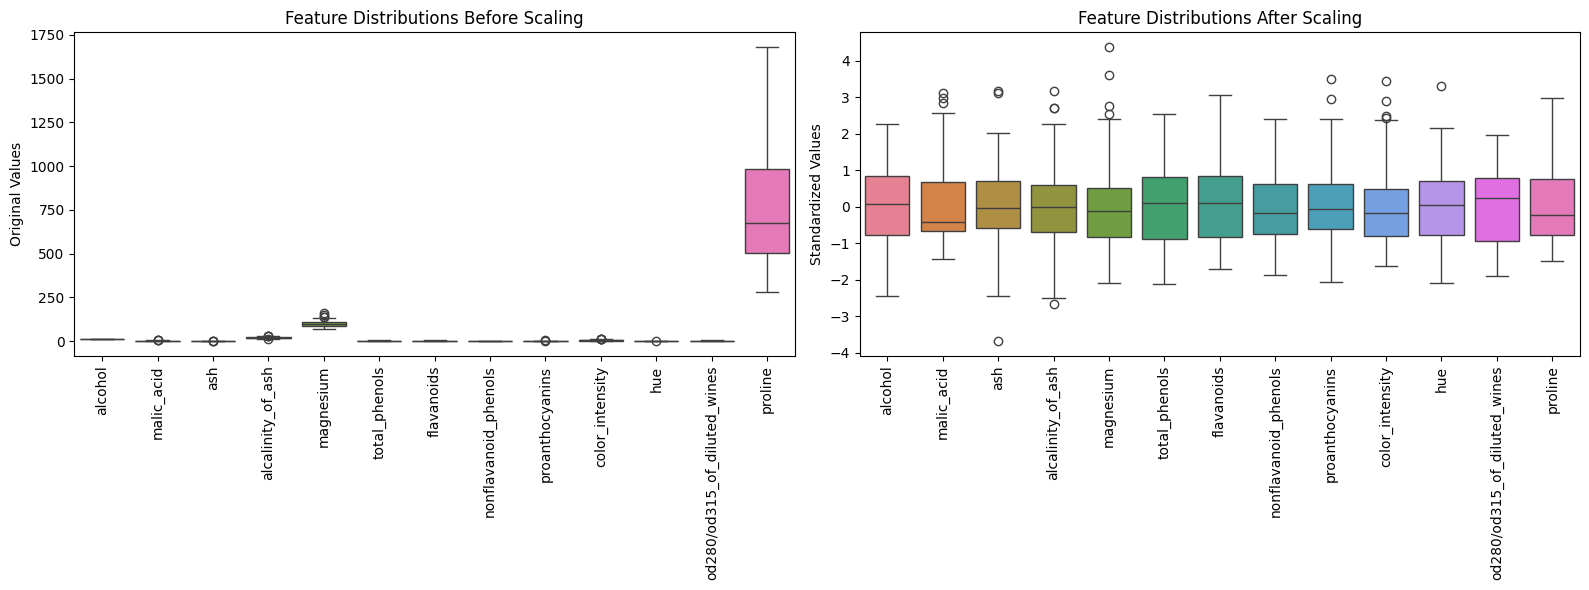

In [2]:
wine = load_wine()
df = pd.DataFrame(wine.data, columns=wine.feature_names)

y = wine.target

print("Dataset Head:")
display(df.head())

print("\nDataset Dimensions:")
print(df.shape)

print("\nDataset Info:")
df.info()

print("\nSummary Statistics:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

X = df.values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

df_scaled = pd.DataFrame(X_scaled, columns=wine.feature_names)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(data=df, ax=ax1)
ax1.set_title("Feature Distributions Before Scaling")
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=90)
ax1.set_ylabel("Original Values")

sns.boxplot(data=df_scaled, ax=ax2)
ax2.set_title("Feature Distributions After Scaling")
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=90)
ax2.set_ylabel("Standardized Values")

plt.tight_layout()
plt.show()


##2.
####In this task, I used K-Means clustering to determine the best number of clusters for the Wine dataset.

####I test values of k from 1 to 10 and calculate inertia for each model. I used these values to create the Elbow Method graph.

####I calculated Silhouette Scores for k from 2 to 10. A higher silhouette score means the clusters are generally better separated.

####I ploted both results side by side and printed the suggested number of clusters from each method. For the Elbow Method, I use a mathematical estimate of the elbow point.

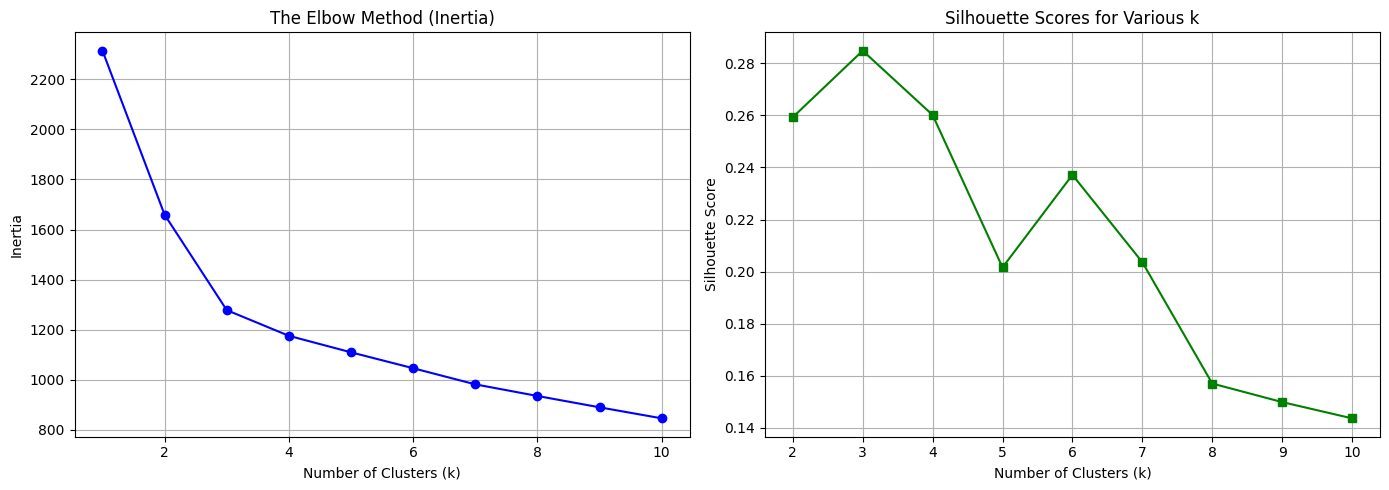

Suggested k from Elbow Method: 3
Optimal k from Silhouette Scores: 3


In [3]:
inertia = []
silhouette_scores = []
K_range = range(2, 11)

for k in range(1, 11):
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_temp.fit(X_scaled)
    inertia.append(kmeans_temp.inertia_)

for k in K_range:
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans_temp.fit_predict(X_scaled)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(range(1, 11), inertia, marker='o', color='b', linestyle='-')
ax1.set_title('The Elbow Method (Inertia)')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia')
ax1.grid(True)

ax2.plot(K_range, silhouette_scores, marker='s', color='g', linestyle='-')
ax2.set_title('Silhouette Scores for Various k')
ax2.set_xlabel('Number of Clusters (k)')
ax2.set_ylabel('Silhouette Score')
ax2.grid(True)

plt.tight_layout()
plt.show()

k_values = np.arange(1, 11)
inertia_scaled = (np.array(inertia) - min(inertia)) / (max(inertia) - min(inertia))
k_scaled = (k_values - 1) / 9

distances = np.abs(1 - k_scaled - inertia_scaled) / np.sqrt(2)

optimal_k_elbow = k_values[np.argmax(distances)]
optimal_k_silhouette = list(K_range)[np.argmax(silhouette_scores)]

print("Suggested k from Elbow Method:", optimal_k_elbow)
print("Optimal k from Silhouette Scores:", optimal_k_silhouette)


##3.
####I used Principal Component Analysis to reduce the 13 standardized chemical features to 2 principal components. I applied K-Means clustering with k=3 to the PCA-transformed data.

####I created a mesh grid and predict the cluster assignment for each point on the grid. This allowed me to visualize the Voronoi decision boundaries. And plotted the wine samples and cluster centers.

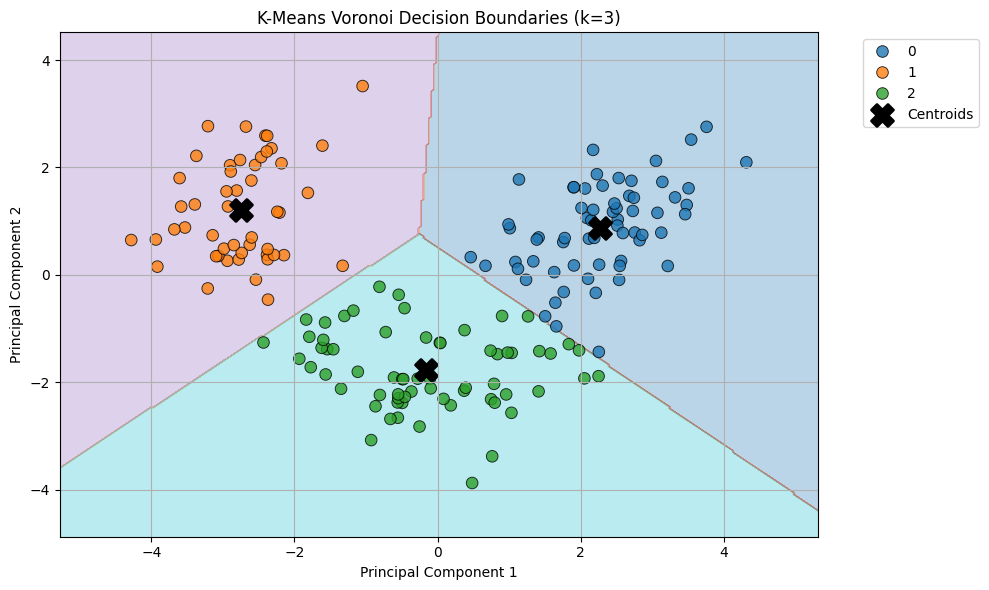

In [4]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

k = 3
kmeans_2d = KMeans(n_clusters=k, random_state=42, n_init=10)
y_pred_2d = kmeans_2d.fit_predict(X_pca)

centroids = kmeans_2d.cluster_centers_

df_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_pca['Cluster'] = y_pred_2d

plt.figure(figsize=(10, 6))

x_min, x_max = X_pca[:, 0].min() - 1, X_pca[:, 0].max() + 1
y_min, y_max = X_pca[:, 1].min() - 1, X_pca[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid_points = np.c_[xx.ravel(), yy.ravel()]
Z = kmeans_2d.predict(grid_points)
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.3, cmap='tab10')

sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='Cluster',
    data=df_pca,
    palette='tab10',
    s=70,
    alpha=0.8,
    edgecolor='k'
)

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker='X',
    s=250,
    linewidths=2,
    color='black',
    label='Centroids'
)

plt.title('K-Means Voronoi Decision Boundaries (k=3)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()


##4.
####I examined the difference between hard and soft clustering using K-Means. I trained a K-Means model with k=3 using all 13 standardized features. I then selected five wine samples from different parts of the dataset.

####I use the transform() method to calculate the distance between each selected sample and the three cluster centroids.

####I created a heatmap displaying these distances. Each row represents a wine sample, and each column represents a cluster center.

Distance Matrix:
[[4.96 6.29 2.06]
 [4.48 5.74 2.3 ]
 [2.98 3.26 4.84]
 [4.9  6.77 5.6 ]
 [5.48 3.11 5.68]]


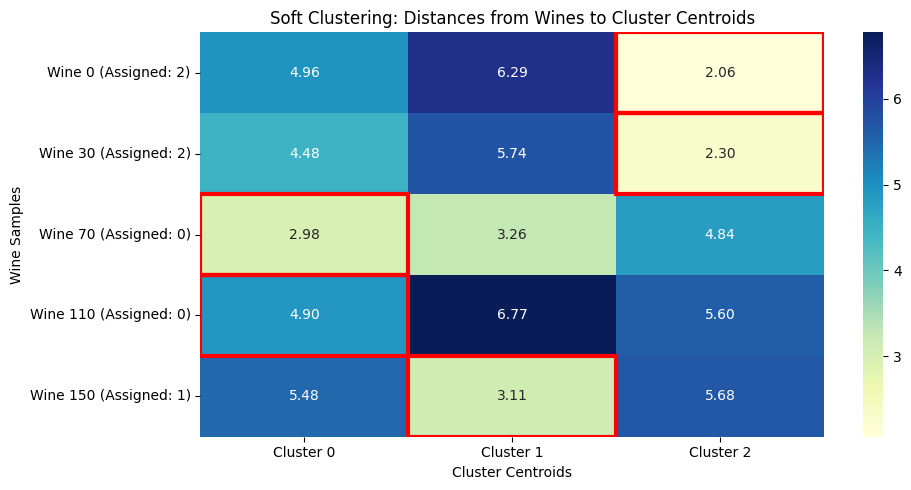

In [5]:
k = 3
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

sample_indices = [0, 30, 70, 110, 150]
X_new_scaled = X_scaled[sample_indices]

distances = kmeans.transform(X_new_scaled)
new_predictions = kmeans.predict(X_new_scaled)

print("Distance Matrix:")
print(np.round(distances, 2))

plt.figure(figsize=(10, 5))

ax = sns.heatmap(
    distances,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    xticklabels=[f"Cluster {i}" for i in range(k)],
    yticklabels=[
        f"Wine {i} (Assigned: {pred})"
        for i, pred in zip(sample_indices, new_predictions)
    ]
)

for i, pred in enumerate(new_predictions):
    ax.add_patch(
        plt.Rectangle(
            (pred, i), 1, 1,
            fill=False,
            edgecolor='red',
            linewidth=3
        )
    )

plt.title("Soft Clustering: Distances from Wines to Cluster Centroids")
plt.xlabel("Cluster Centroids")
plt.ylabel("Wine Samples")
plt.tight_layout()
plt.show()


##5.
####I applied DBSCAN clustering to the 13 standardized features of the Wine dataset. Unlike K-Means, DBSCAN does not require us to specify the number of clusters in advance. Instead, it finds groups of samples based on their density.

####I tested two combinations of the DBSCAN parameters and printed the number of clusters and noise points for each combination.

####I fit DBSCAN using eps=2.0 and min_samples=5. And I visualized the cluster assignments using the two PCA components. Core points are shown as circles, border points are triangles, and noise points are black X marks. The clustering is performed using all 13 scaled features.

eps=2.0, min_samples=5
Estimated number of clusters: 5
Estimated number of noise points: 85

eps=2.5, min_samples=8
Estimated number of clusters: 2
Estimated number of noise points: 30

Estimated number of clusters: 5
Estimated number of noise points: 85


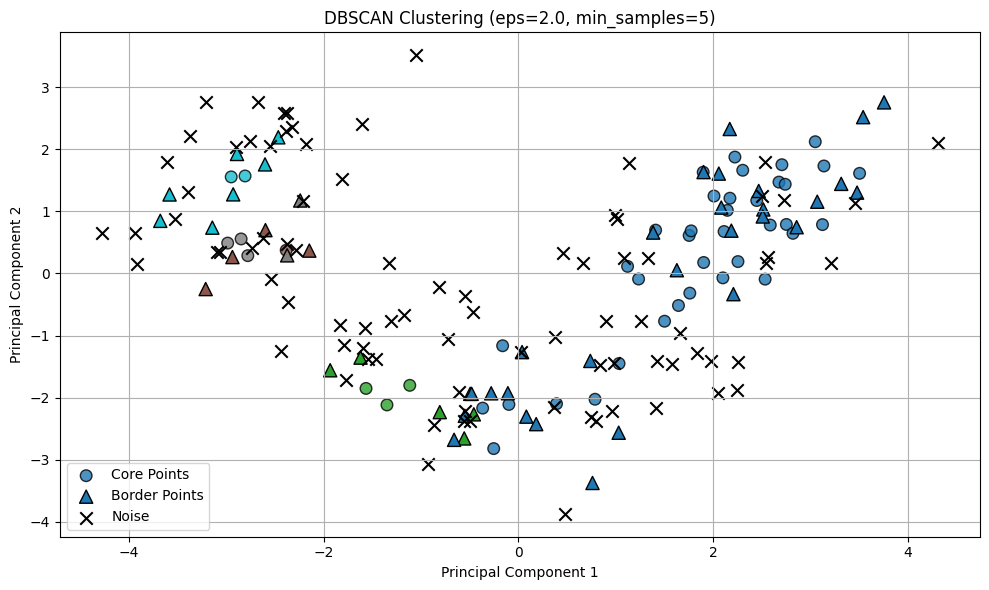

In [6]:
for eps, min_samples in [(2.0, 5), (2.5, 8)]:
    dbscan_temp = DBSCAN(eps=eps, min_samples=min_samples)
    labels = dbscan_temp.fit_predict(X_scaled)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)

    print(f"eps={eps}, min_samples={min_samples}")
    print(f"Estimated number of clusters: {n_clusters}")
    print(f"Estimated number of noise points: {n_noise}")
    print()

dbscan = DBSCAN(eps=2.0, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)

n_clusters_ = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise_ = list(dbscan_labels).count(-1)

print(f"Estimated number of clusters: {n_clusters_}")
print(f"Estimated number of noise points: {n_noise_}")

core_mask = np.zeros(len(X_scaled), dtype=bool)
core_mask[dbscan.core_sample_indices_] = True

noise_mask = dbscan_labels == -1
border_mask = ~core_mask & ~noise_mask

plt.figure(figsize=(10, 6))

plt.scatter(
    X_pca[core_mask, 0],
    X_pca[core_mask, 1],
    c=dbscan_labels[core_mask],
    cmap='tab10',
    s=70,
    alpha=0.8,
    edgecolor='k',
    label='Core Points'
)

plt.scatter(
    X_pca[border_mask, 0],
    X_pca[border_mask, 1],
    c=dbscan_labels[border_mask],
    cmap='tab10',
    marker='^',
    s=90,
    edgecolor='k',
    label='Border Points'
)

plt.scatter(
    X_pca[noise_mask, 0],
    X_pca[noise_mask, 1],
    color='black',
    marker='x',
    s=80,
    label='Noise'
)

plt.title('DBSCAN Clustering (eps=2.0, min_samples=5)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


##6.
####In this task, I apply HDBSCAN clustering to the Wine dataset. HDBSCAN is an improved density-based clustering method that can identify groups with different densities.

####Unlike DBSCAN, HDBSCAN does not require a fixed eps parameter. Instead, it examines the data at different density levels and selects clusters that remain stable.

####I fit the HDBSCAN model using all 13 standardized features and set min_cluster_size=5. I calculated and printed the total number of identified clusters and noise points. Noise points are samples that do not belong to any cluster and received the label -1.

####I displayed the clustering results using the two PCA components. Each cluster is represented by a different color, and noise points are shown as black X marks.

Estimated number of HDBSCAN clusters: 2
Estimated number of HDBSCAN noise points: 58


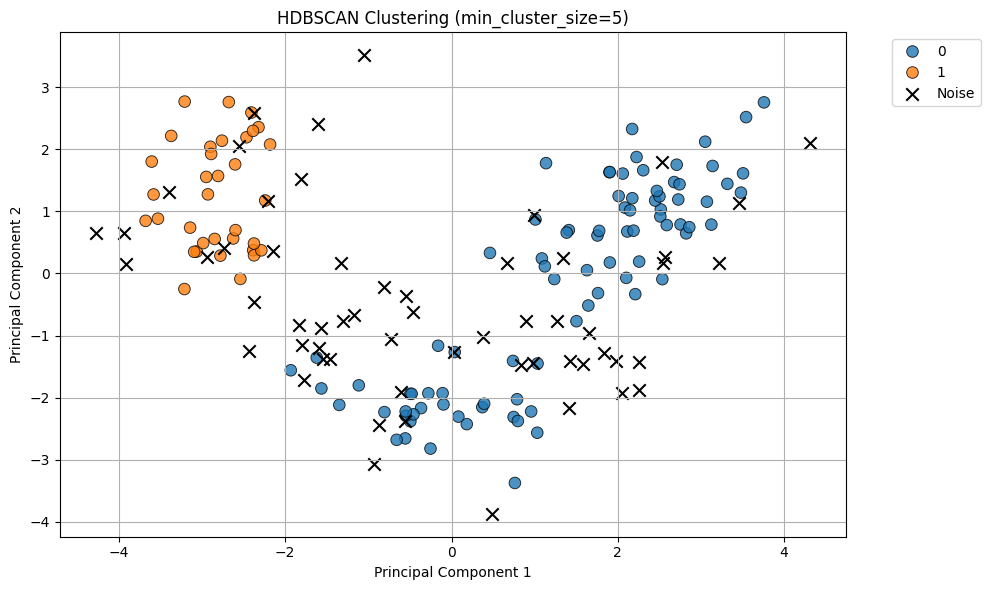

In [7]:
hdbscan_model = HDBSCAN(min_cluster_size=5)
hdbscan_labels = hdbscan_model.fit_predict(X_scaled)

n_hdbscan_clusters_ = len(set(hdbscan_labels)) - (1 if -1 in hdbscan_labels else 0)
n_hdbscan_noise_ = list(hdbscan_labels).count(-1)

print(f"Estimated number of HDBSCAN clusters: {n_hdbscan_clusters_}")
print(f"Estimated number of HDBSCAN noise points: {n_hdbscan_noise_}")

df_hdbscan = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_hdbscan['Cluster'] = hdbscan_labels

cluster_mask = hdbscan_labels != -1
noise_mask = hdbscan_labels == -1

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='Cluster',
    data=df_hdbscan[cluster_mask],
    palette='tab10',
    s=70,
    alpha=0.8,
    edgecolor='k',
    legend='full'
)

plt.scatter(
    X_pca[noise_mask, 0],
    X_pca[noise_mask, 1],
    color='black',
    marker='x',
    s=80,
    label='Noise'
)

plt.title('HDBSCAN Clustering (min_cluster_size=5)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()


##7.
####Here I used hierarchical clustering to examine how wine samples are grouped based on their chemical features.

####I calculated a hierarchical clustering matrix using the linkage() function. I use the single method, which joins two groups based on the shortest distance between their samples.

####Next, I created a dendrogram to visualize the hierarchical structure. The height of each connection represents the distance at which the groups merge. This visualization is also related to HDBSCAN because HDBSCAN uses a hierarchical approach to identify stable groups.

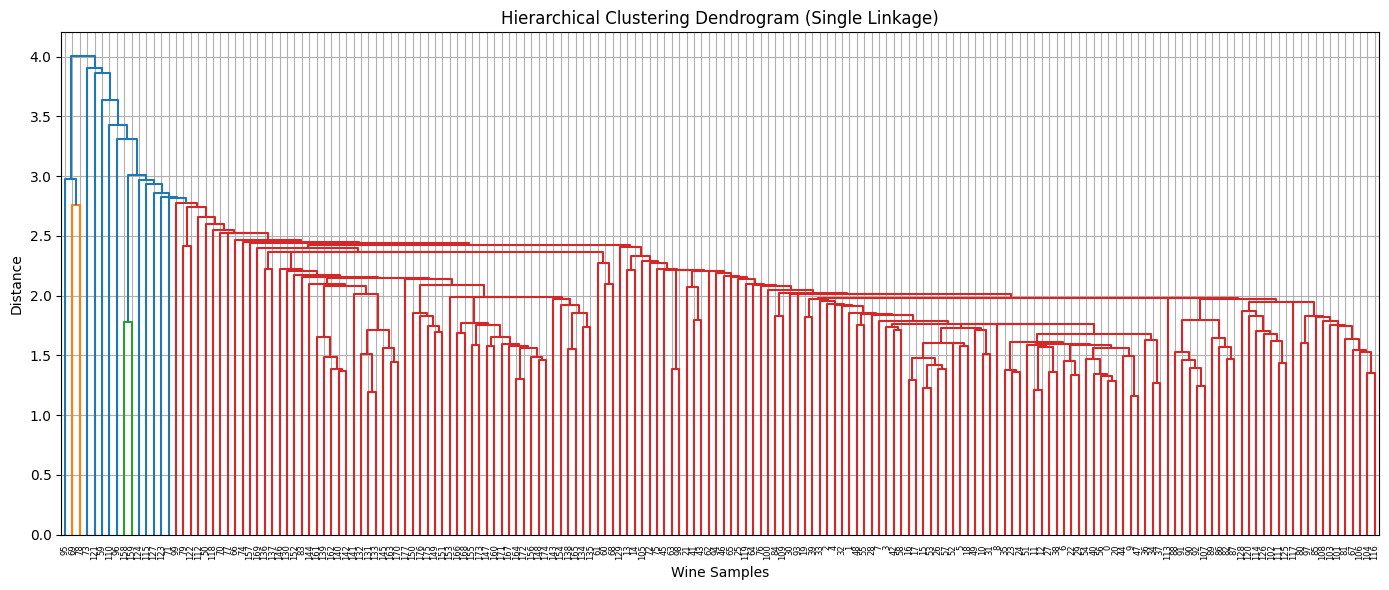

In [8]:
linkage_matrix = linkage(X_scaled, method='single')

plt.figure(figsize=(14, 6))

dendrogram(
    linkage_matrix,
    leaf_rotation=90,
    leaf_font_size=6
)

plt.title('Hierarchical Clustering Dendrogram (Single Linkage)')
plt.xlabel('Wine Samples')
plt.ylabel('Distance')
plt.grid(True)
plt.tight_layout()
plt.show()


##8.

####Here I evaluated how useful the clustering results are for predicting the actual wine cultivars. I used the clusters from K-Means, DBSCAN, and HDBSCAN as categorical features.

####I created an 80/20 train/test split using stratification. This makes sure that all three actual wine classes are represented proportionally in both training and testing datasets.

####I used the cluster labels produced by each algorithm as input features. Because these labels represent categories rather than numerical measurements, I apply OneHotEncoder to convert them into a format suitable for classification.

####I then trained a RF classifier separately for each clustering algorithm and used it to predict the actual wine classes. And calculated classification accuracy by comparing the predictions with the true class labels. Also calculated Silhouette Scores to evaluate how well the clusters are separated. For DBSCAN and HDBSCAN, I excluded noise points from this calculation.

####At the end I created two bar charts comparing classification accuracy and Silhouette Scores for the three clustering algorithms.

K-Means:
Classification Accuracy: 0.972
Silhouette Score: 0.285

DBSCAN:
Classification Accuracy: 0.694
Silhouette Score: 0.240

HDBSCAN:
Classification Accuracy: 0.750
Silhouette Score: 0.352



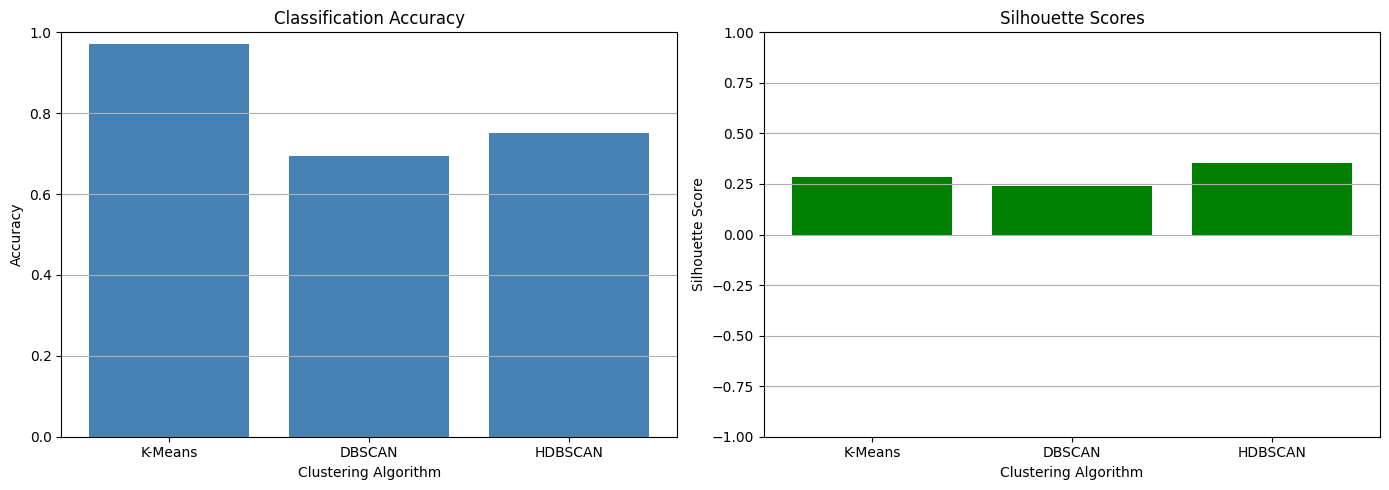

In [9]:
cluster_results = {
    'K-Means': kmeans_labels,
    'DBSCAN': dbscan_labels,
    'HDBSCAN': hdbscan_labels
}

indices = np.arange(len(y))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=y
)

y_train = y[train_idx]
y_test = y[test_idx]

accuracy_scores = []
cluster_silhouette_scores = []

for name, labels in cluster_results.items():

    X_train_clusters = labels[train_idx].reshape(-1, 1)
    X_test_clusters = labels[test_idx].reshape(-1, 1)

    encoder = OneHotEncoder(handle_unknown='ignore')
    X_train_encoded = encoder.fit_transform(X_train_clusters)
    X_test_encoded = encoder.transform(X_test_clusters)

    rf = RandomForestClassifier(n_estimators=100, random_state=42)
    rf.fit(X_train_encoded, y_train)

    y_pred = rf.predict(X_test_encoded)

    accuracy = accuracy_score(y_test, y_pred)
    accuracy_scores.append(accuracy)

    valid_mask = labels != -1
    valid_labels = labels[valid_mask]
    valid_X = X_scaled[valid_mask]

    if 1 < len(set(valid_labels)) < len(valid_labels):
        score = silhouette_score(valid_X, valid_labels)
    else:
        score = np.nan

    cluster_silhouette_scores.append(score)

    print(f"{name}:")
    print(f"Classification Accuracy: {accuracy:.3f}")
    print(f"Silhouette Score: {score:.3f}")
    print()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.bar(cluster_results.keys(), accuracy_scores, color='steelblue')
ax1.set_title('Classification Accuracy')
ax1.set_xlabel('Clustering Algorithm')
ax1.set_ylabel('Accuracy')
ax1.set_ylim(0, 1)
ax1.grid(axis='y')

ax2.bar(cluster_results.keys(), cluster_silhouette_scores, color='green')
ax2.set_title('Silhouette Scores')
ax2.set_xlabel('Clustering Algorithm')
ax2.set_ylabel('Silhouette Score')
ax2.set_ylim(-1, 1)
ax2.grid(axis='y')

plt.tight_layout()
plt.show()